# Antriebsarten und Einwohnerdichte

Untersucht wird, ob der Anteil von Elektro, Hybrid, Benzin und Diesel im Personenwagenbestand mit der Einwohnerdichte zusammenhängt und wie sich dieser Zusammenhang von 2010 bis 2024 verändert hat.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJEKT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJEKT_ROOT))

from src.pipeline import run_pipeline
from src.transform import daten_transformieren

FARBEN = {
    "Elektro": "#2a9d8f",
    "Hybrid": "#e9c46a",
    "Benzin": "#e76f51",
    "Diesel": "#577590",
}

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
daten = daten_transformieren(run_pipeline())

personenwagen = daten.loc[
    (daten["Fahrzeuggruppe"] == "Personenwagen")
    & (daten["KTNR"] == 1)
].copy()

personenwagen["Gesamtbestand"] = personenwagen.groupby(
    ["gemeinde_nr", "Jahr"]
)["Fahrzeuge"].transform("sum")

def antriebsart_zuordnen(treibstoff):
    if treibstoff == "Elektrisch":
        return "Elektro"
    if "Hybrid" in treibstoff:
        return "Hybrid"
    if treibstoff in ["Benzin", "Diesel"]:
        return treibstoff
    return pd.NA

personenwagen["Antriebsart"] = personenwagen["Treibstoff"].apply(
    antriebsart_zuordnen
)

analyse = (
    personenwagen.dropna(subset=["Antriebsart"])
    .groupby(
        [
            "gemeinde_nr",
            "Gemeinde",
            "Jahr",
            "Antriebsart",
            "Einwohner",
            "Flaeche_km2",
            "Einwohnerdichte",
            "Gesamtbestand",
        ],
        as_index=False,
    )["Fahrzeuge"]
    .sum()
)

analyse["Anteil_Prozent"] = (
    analyse["Fahrzeuge"] / analyse["Gesamtbestand"] * 100
)

anteil_2010 = (
    analyse.loc[analyse["Jahr"] == 2010, [
        "gemeinde_nr", "Antriebsart", "Anteil_Prozent"
    ]]
    .rename(columns={"Anteil_Prozent": "Anteil_2010"})
)
analyse = analyse.merge(
    anteil_2010,
    on=["gemeinde_nr", "Antriebsart"],
    how="left",
)
analyse["Veraenderung_Seit_2010_Prozentpunkte"] = (
    analyse["Anteil_Prozent"] - analyse["Anteil_2010"]
)

## Elektrifizierte und fossile Antriebe
Elektro und Hybrid werden als elektrifiziert zusammengefasst, Benzin und Diesel als fossil. Die Werte bleiben Anteile an jährlichen Bestandsmessungen und sind keine Verkaufszahlen.

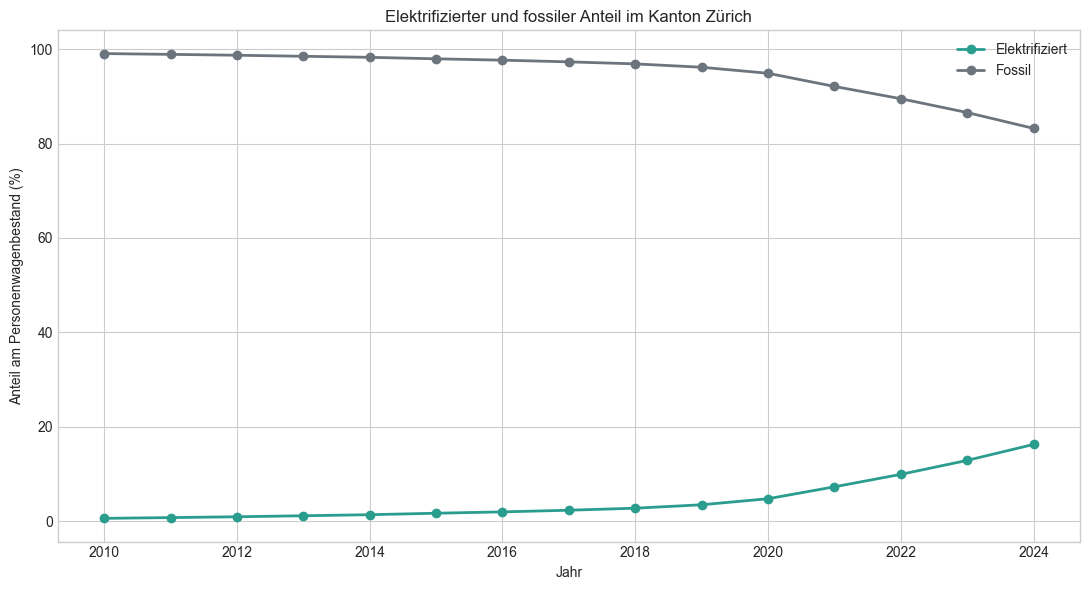

In [3]:
entwicklung = (
    analyse.groupby(["Jahr", "Antriebsart"], as_index=False)["Fahrzeuge"]
    .sum()
)
gesamtbestand = (
    personenwagen.groupby("Jahr", as_index=False)["Fahrzeuge"]
    .sum()
    .rename(columns={"Fahrzeuge": "Gesamtbestand"})
)
entwicklung = entwicklung.merge(gesamtbestand, on="Jahr")
entwicklung["Anteil_Prozent"] = (
    entwicklung["Fahrzeuge"] / entwicklung["Gesamtbestand"] * 100
)

entwicklung_breit = (
    entwicklung.pivot(
        index="Jahr",
        columns="Antriebsart",
        values="Anteil_Prozent",
    )
    .fillna(0)
)
entwicklung_breit["Elektrifiziert"] = (
    entwicklung_breit["Elektro"] + entwicklung_breit["Hybrid"]
)
entwicklung_breit["Fossil"] = (
    entwicklung_breit["Benzin"] + entwicklung_breit["Diesel"]
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    entwicklung_breit.index,
    entwicklung_breit["Elektrifiziert"],
    marker="o",
    linewidth=2,
    label="Elektrifiziert",
    color="#2a9d8f",
)
ax.plot(
    entwicklung_breit.index,
    entwicklung_breit["Fossil"],
    marker="o",
    linewidth=2,
    label="Fossil",
    color="#6c757d",
)
ax.set(
    title="Elektrifizierter und fossiler Anteil im Kanton Zürich",
    xlabel="Jahr",
    ylabel="Anteil am Personenwagenbestand (%)",
)
ax.legend()
plt.tight_layout()
plt.show()

## Entwicklung der Antriebsanteile
Die Grafik zeigt, wie sich die Anteile der vier Antriebsarten am gesamten Personenwagenbestand des Kantons Zürich zwischen 2010 und 2024 entwickelt haben.

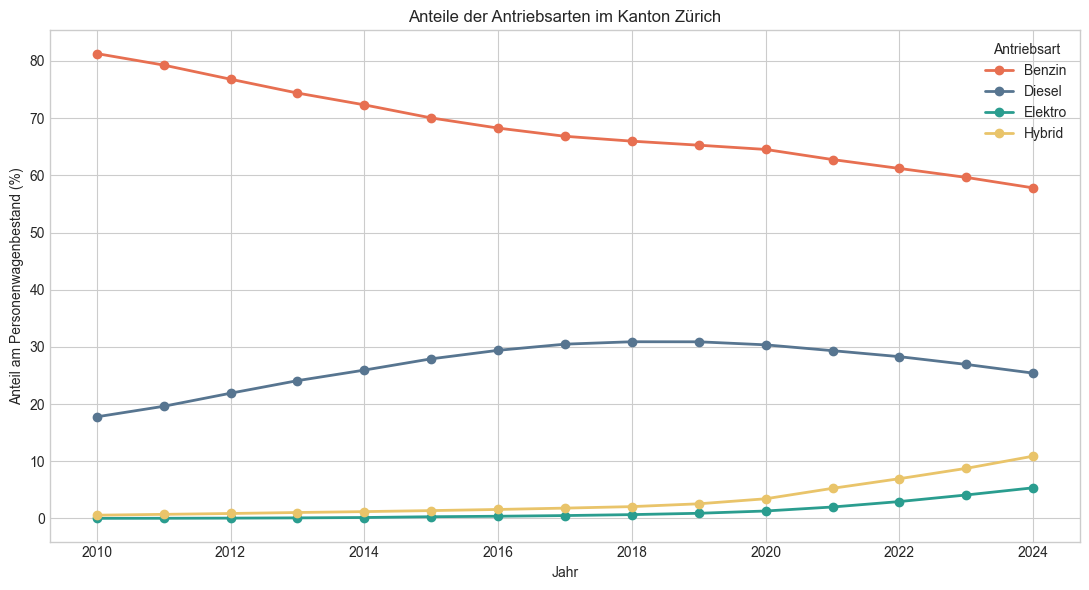

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
for antriebsart, gruppe in entwicklung.groupby("Antriebsart"):
    ax.plot(
        gruppe["Jahr"],
        gruppe["Anteil_Prozent"],
        marker="o",
        linewidth=2,
        label=antriebsart,
        color=FARBEN[antriebsart],
    )

ax.set(
    title="Anteile der Antriebsarten im Kanton Zürich",
    xlabel="Jahr",
    ylabel="Anteil am Personenwagenbestand (%)",
)
ax.legend(title="Antriebsart")
plt.tight_layout()
plt.show()

## Einwohnerdichte und Antriebsanteil: 2010 gegenüber 2024
Jeder Punkt steht für eine Gemeinde. Die Linien zeigen die allgemeine Richtung des Zusammenhangs; die logarithmische x-Achse macht Gemeinden mit sehr unterschiedlicher Dichte vergleichbar.

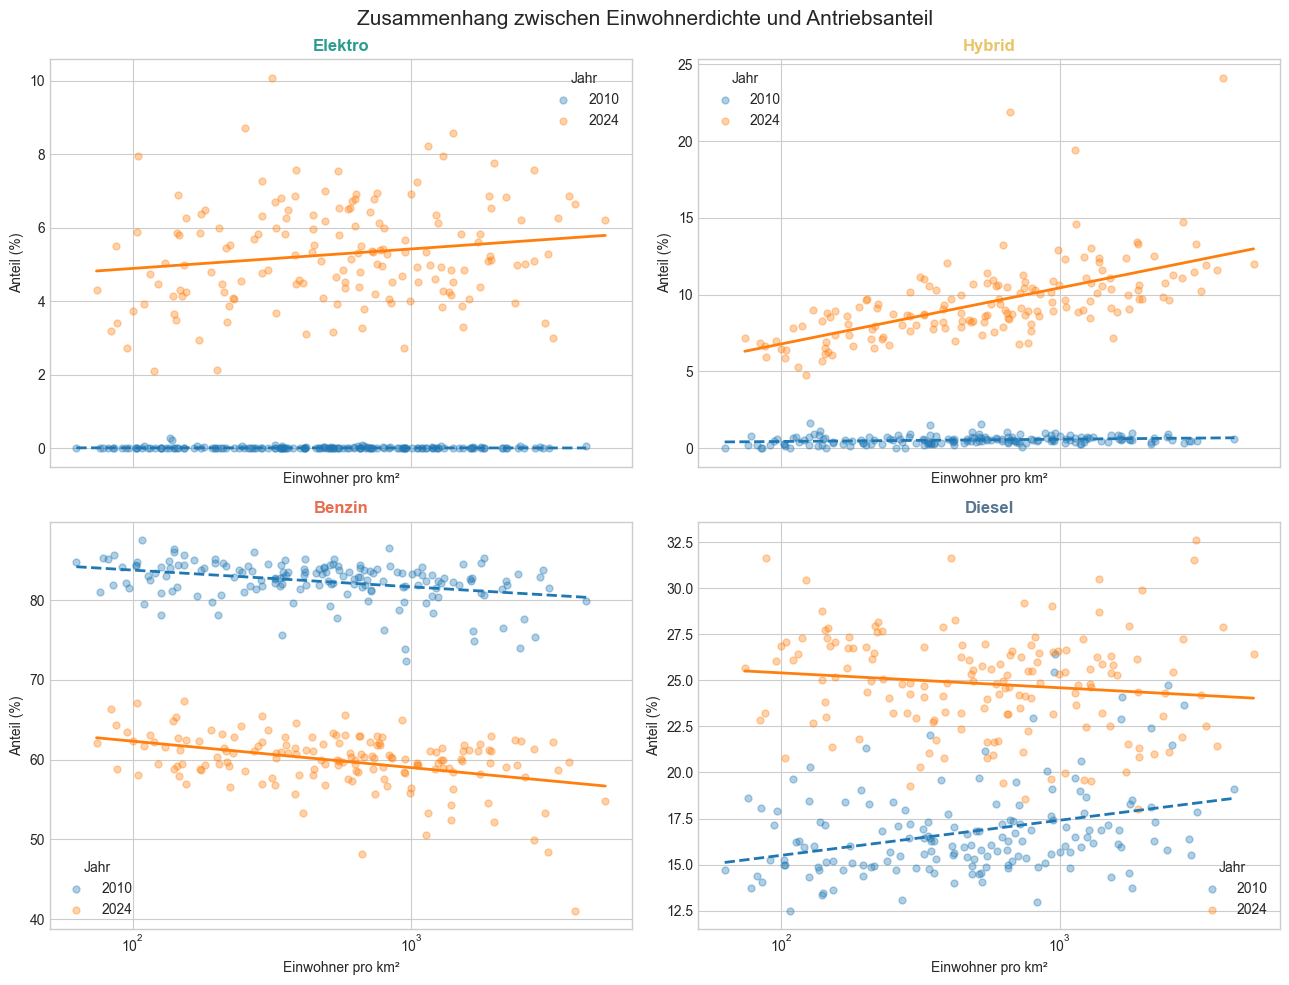

In [5]:
fig, achsen = plt.subplots(2, 2, figsize=(13, 10), sharex=True)

for achse, antriebsart in zip(achsen.flat, FARBEN):
    for jahr, linienart in [(2010, "--"), (2024, "-")]:
        auswahl = analyse.loc[
            (analyse["Antriebsart"] == antriebsart)
            & (analyse["Jahr"] == jahr)
        ]

        achse.scatter(
            auswahl["Einwohnerdichte"],
            auswahl["Anteil_Prozent"],
            alpha=0.35,
            s=25,
            label=str(jahr),
        )

        x = np.log10(auswahl["Einwohnerdichte"])
        y = auswahl["Anteil_Prozent"]
        steigung, achsenabschnitt = np.polyfit(x, y, 1)
        x_linie = np.geomspace(
            auswahl["Einwohnerdichte"].min(),
            auswahl["Einwohnerdichte"].max(),
            100,
        )
        achse.plot(
            x_linie,
            steigung * np.log10(x_linie) + achsenabschnitt,
            linestyle=linienart,
            linewidth=2,
        )

    achse.set_xscale("log")
    achse.set_title(antriebsart, color=FARBEN[antriebsart], fontweight="bold")
    achse.set_xlabel("Einwohner pro km²")
    achse.set_ylabel("Anteil (%)")
    achse.legend(title="Jahr")

fig.suptitle("Zusammenhang zwischen Einwohnerdichte und Antriebsanteil", fontsize=15)
plt.tight_layout()
plt.show()

## Veränderung des Zusammenhangs über die Zeit
Die Korrelation zeigt Richtung und Stärke des statistischen Zusammenhangs. Positive Werte bedeuten höhere Anteile in dichteren Gemeinden, negative Werte höhere Anteile in weniger dichten Gemeinden. Sie beschreibt einen Zusammenhang, aber keine Ursache.

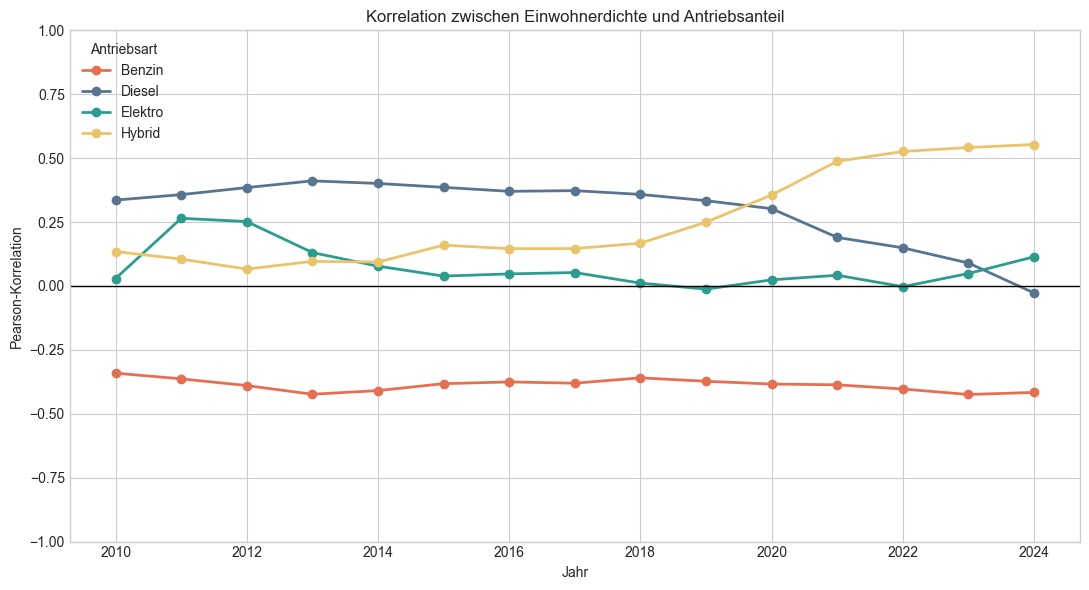

In [6]:
korrelationen = []

for (jahr, antriebsart), gruppe in analyse.groupby(["Jahr", "Antriebsart"]):
    korrelationen.append(
        {
            "Jahr": jahr,
            "Antriebsart": antriebsart,
            "Korrelation": gruppe["Einwohnerdichte"].corr(
                gruppe["Anteil_Prozent"]
            ),
        }
    )

korrelationen = pd.DataFrame(korrelationen)

fig, ax = plt.subplots(figsize=(11, 6))
for antriebsart, gruppe in korrelationen.groupby("Antriebsart"):
    ax.plot(
        gruppe["Jahr"],
        gruppe["Korrelation"],
        marker="o",
        linewidth=2,
        label=antriebsart,
        color=FARBEN[antriebsart],
    )

ax.axhline(0, color="black", linewidth=1)
ax.set(
    title="Korrelation zwischen Einwohnerdichte und Antriebsanteil",
    xlabel="Jahr",
    ylabel="Pearson-Korrelation",
    ylim=(-1, 1),
)
ax.legend(title="Antriebsart")
plt.tight_layout()
plt.show()

## Antriebsanteile nach Einwohnerdichte 2024
Die Gemeinden werden in vier gleich grosse Dichtegruppen eingeteilt. Gezeigt wird der durchschnittliche Anteil einer Antriebsart in einer Gemeinde der jeweiligen Gruppe.

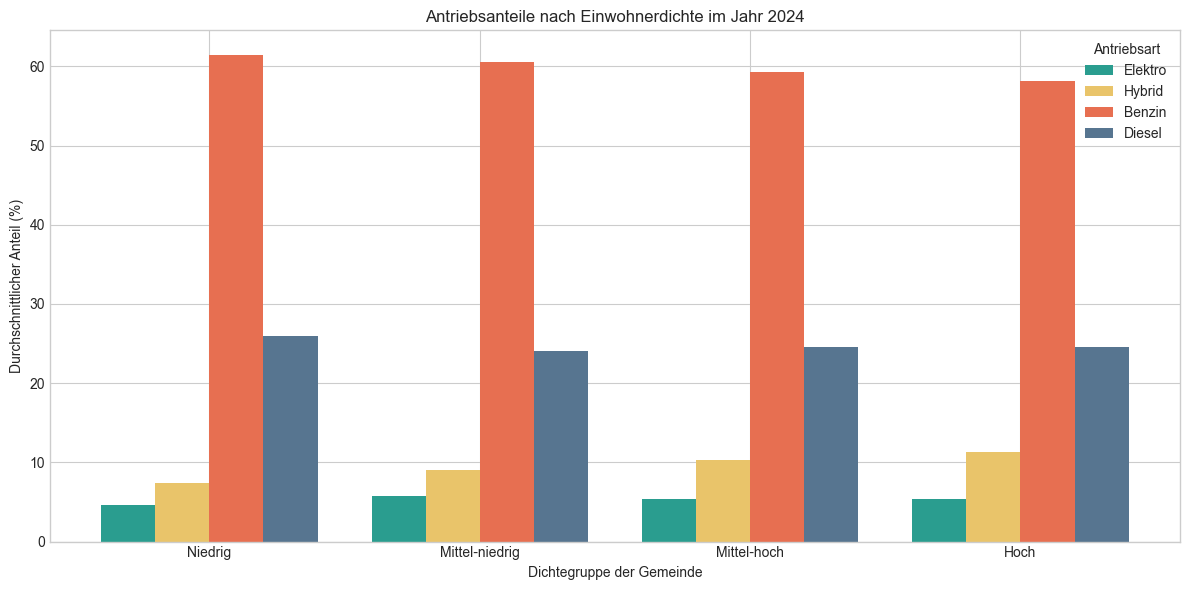

In [7]:
dichtegruppen = ["Niedrig", "Mittel-niedrig", "Mittel-hoch", "Hoch"]
gemeinden_2024 = (
    analyse.loc[analyse["Jahr"] == 2024, [
        "gemeinde_nr", "Einwohnerdichte"
    ]]
    .drop_duplicates()
)
gemeinden_2024["Dichtegruppe"] = pd.qcut(
    gemeinden_2024["Einwohnerdichte"],
    q=4,
    labels=dichtegruppen,
)
vergleich_2024 = (
    analyse.loc[analyse["Jahr"] == 2024]
    .merge(
        gemeinden_2024[["gemeinde_nr", "Dichtegruppe"]],
        on="gemeinde_nr",
    )
    .groupby(
        ["Dichtegruppe", "Antriebsart"],
        observed=True,
    )["Anteil_Prozent"]
    .mean()
    .unstack(fill_value=0)
    .reindex(dichtegruppen)
)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(dichtegruppen))
breite = 0.2

for position, antriebsart in enumerate(FARBEN):
    ax.bar(
        x + (position - 1.5) * breite,
        vergleich_2024[antriebsart],
        width=breite,
        label=antriebsart,
        color=FARBEN[antriebsart],
    )

ax.set_xticks(x, dichtegruppen)
ax.set(
    title="Antriebsanteile nach Einwohnerdichte im Jahr 2024",
    xlabel="Dichtegruppe der Gemeinde",
    ylabel="Durchschnittlicher Anteil (%)",
)
ax.legend(title="Antriebsart")
plt.tight_layout()
plt.show()